<a href="https://colab.research.google.com/github/Faheemmundoli/house-price-prediction-ml/blob/main/Lab_11_and_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Faheem M 2427010572

# Lab 11 & 12: K-Means, K-Means++ and DBSCAN Clustering

Objectives:
1. Perform K-Means clustering (random initialization).
2. Perform K-Means++ clustering and compare it with K-Means.
3. Apply DBSCAN and identify noise points.
4. Compare the three algorithms.

## K-Means, K-Means++ and DBSCAN :
K-Means starts from random centres. K-Means++ starts from well-spread centres. DBSCAN groups dense regions and marks isolated points as noise (black). PCA reduces the data to 2 dimensions so that the clusters can be drawn.

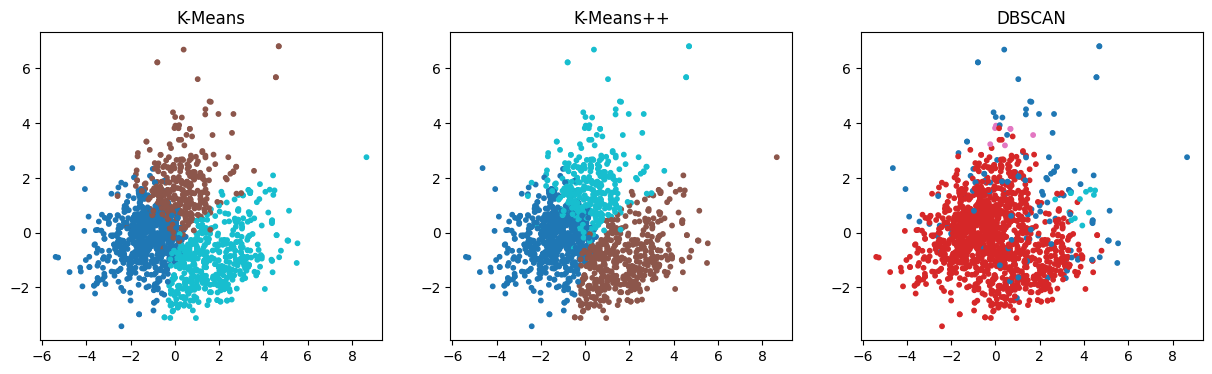

K-Means inertia  : 12629.925637954018
K-Means++ inertia: 12629.974591732656
DBSCAN labels    : {np.int64(0), np.int64(1), np.int64(2), np.int64(-1)}


In [ ]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Run the three algorithms
km = KMeans(n_clusters=3, init='random', n_init=10, random_state=42).fit(X_scaled)
kmpp = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42).fit(X_scaled)
db = DBSCAN(eps=2, min_samples=5).fit(X_scaled)

# 2. Reduce to 2 columns only so we can draw the graph
X_2d = PCA(n_components=2).fit_transform(X_scaled)

# 3. Plot all three
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=km.labels_, cmap='tab10', s=10)
plt.title('K-Means')

plt.subplot(1, 3, 2)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=kmpp.labels_, cmap='tab10', s=10)
plt.title('K-Means++')

plt.subplot(1, 3, 3)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=db.labels_, cmap='tab10', s=10)
plt.title('DBSCAN')

plt.show()

# 4. Results
print("K-Means inertia  :", km.inertia_)
print("K-Means++ inertia:", kmpp.inertia_)
print("DBSCAN labels    :", set(db.labels_))   # -1 means noise